# Économie du crédit : prédire le défaut de remboursement
## Premier avancement — Master MECEN, 11 novembre 2026
**Question :** dans quelle mesure l'historique de remboursement et la situation financière permettent-ils d'identifier les clients qui feront défaut le mois suivant ?

L'enjeu économique est le compromis entre risque de crédit et accès au financement. Une erreur de non-détection peut entraîner une perte pour le prêteur ; une fausse alerte peut pénaliser un client solvable. Le dataset ne contient ni pertes réalisées ni décisions de refus : on ne peut donc pas mesurer directement un gain financier ou un effet sur le rationnement du crédit.

Source officielle : https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients — DOI : 10.24432/C55S3H, licence CC BY 4.0. Données taïwanaises, historiques mensuels d'avril à septembre 2005. Il s'agit d'un téléchargement de données ouvertes, pas d'un web scraping.

**État du travail :** audit, EDA et premières estimations exécutés ; optimisation et évaluation finale non réalisées. Les résultats ci-dessous portent sur la validation, jamais sur le test.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, PrecisionRecallDisplay)
ROOT=Path.cwd()
if ROOT.name!='projet_economie_credit': ROOT=ROOT/'projet_economie_credit'
plt.rcParams.update({'figure.dpi':140,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
source=ROOT/'data'/'default of credit card clients.xls'
df=pd.read_excel(source,header=1).rename(columns={'default payment next month':'DEFAULT'})
df.to_csv(ROOT/'data'/'credit_clients.csv',index=False)
print('Dimensions :',df.shape)
print('Valeurs manquantes :',int(df.isna().sum().sum()))
print('Identifiants uniques :',df.ID.nunique())
print('Doublons exacts hors ID :',int(df.drop(columns='ID').duplicated().sum()))
print('Effectifs de la cible :',df.DEFAULT.value_counts().sort_index().to_dict())
print('Taux de défaut :',round(100*df.DEFAULT.mean(),2),'%')
print('Codes EDUCATION :',df.EDUCATION.value_counts().sort_index().to_dict())
print('Codes MARRIAGE :',df.MARRIAGE.value_counts().sort_index().to_dict())
print('Codes PAY_0 :',df.PAY_0.value_counts().sort_index().to_dict())
df.describe().to_csv(ROOT/'statistiques_descriptives.csv')

Dimensions : (30000, 25)
Valeurs manquantes : 0
Identifiants uniques : 30000
Doublons exacts hors ID : 35
Effectifs de la cible : {0: 23364, 1: 6636}
Taux de défaut : 22.12 %
Codes EDUCATION : {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
Codes MARRIAGE : {0: 54, 1: 13659, 2: 15964, 3: 323}
Codes PAY_0 : {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


## Audit et règles de nettoyage
- `ID` est un identifiant : il ne doit pas être utilisé comme prédicteur.
- Les 35 répétitions exactes hors ID ne prouvent pas des erreurs : des individus peuvent partager les mêmes caractéristiques. On les conserve, mais les profils explicatifs identiques restent dans la même partition et le même pli de validation croisée.
- `EDUCATION` comporte des codes 0, 5 et 6 absents des quatre modalités décrites par UCI : regroupement en catégorie « non documentée », sans inventer leur sens. `MARRIAGE=0` reste une catégorie non documentée.
- Les codes de remboursement sont traités comme catégories. Les valeurs -2 et 0 ne sont pas définies dans la notice UCI consultée ; elles sont conservées sans leur attribuer une interprétation non vérifiée.
- Les montants négatifs et les valeurs extrêmes ne sont pas supprimés automatiquement. Leur signification et leur influence restent à examiner.
- Le sexe, l'âge et les caractéristiques sociales exigent une analyse de sensibilité et des erreurs par groupe avant toute conclusion opérationnelle.

Un modèle qui prédit toujours « sans défaut » atteint 77.88% d'exactitude, mais ne détecte aucun défaut.


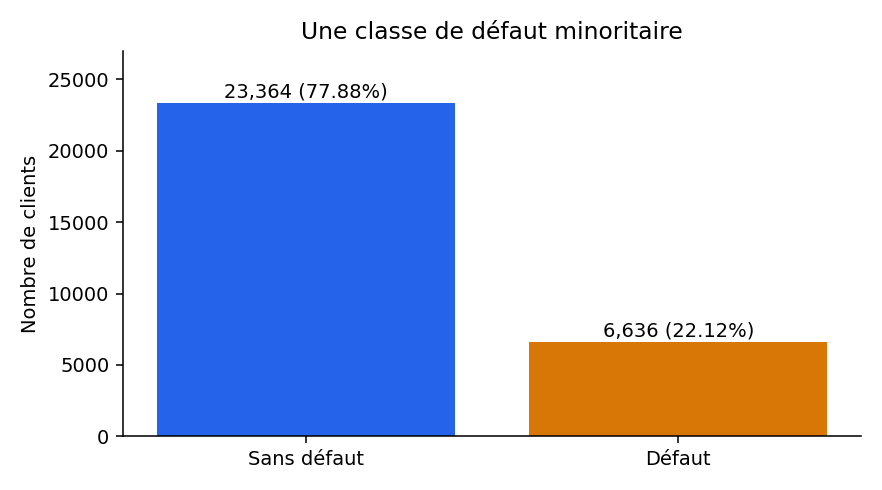

In [2]:
fig,ax=plt.subplots(figsize=(6.3,3.5))
counts=df.DEFAULT.value_counts().sort_index()
ax.bar(['Sans défaut','Défaut'],counts,color=['#2563eb','#d97706'])
for i,v in enumerate(counts): ax.text(i,v+350,f'{v:,} ({v/len(df):.2%})',ha='center')
ax.set(ylabel='Nombre de clients',title='Une classe de défaut minoritaire',ylim=(0,27000))
fig.tight_layout();fig.savefig(ROOT/'figures'/'01_classes.png');plt.close(fig)
print('Un modèle qui prédit toujours « sans défaut » atteint',f'{1-df.DEFAULT.mean():.2%}',"d'exactitude, mais ne détecte aucun défaut.")

        size    mean
PAY_0               
-2      2759  0.1323
-1      5686  0.1678
 0     14737  0.1281
 1      3688  0.3395
 2      2667  0.6914
 3       322  0.7578
 4        76  0.6842
 5        26  0.5000
 6        11  0.5455
 7         9  0.7778
 8        19  0.5789


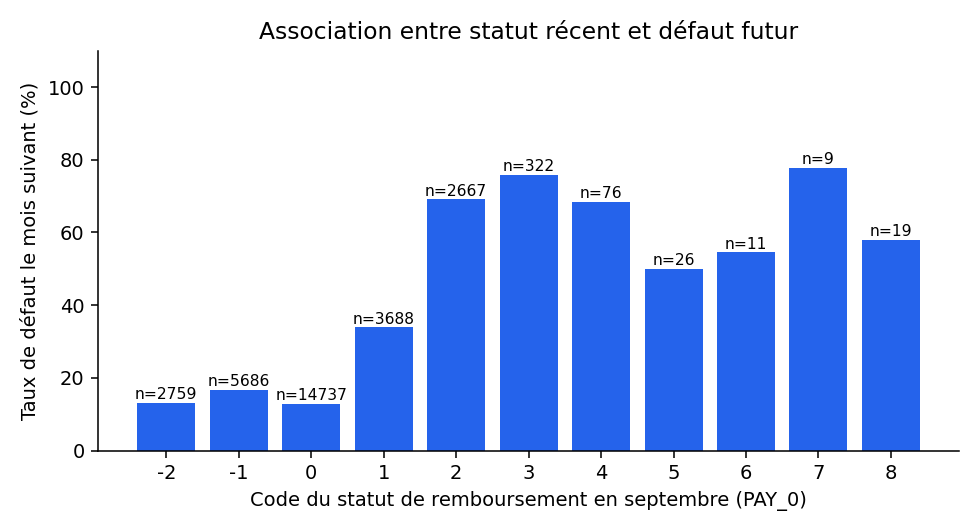

In [3]:
eda=df.groupby('PAY_0').DEFAULT.agg(['size','mean'])
print(eda.round(4).to_string())
fig,ax=plt.subplots(figsize=(7,3.8))
ax.bar(eda.index.astype(str),100*eda['mean'],color='#2563eb')
ax.set(xlabel='Code du statut de remboursement en septembre (PAY_0)',ylabel='Taux de défaut le mois suivant (%)',title='Association entre statut récent et défaut futur')
for i,(_,r) in enumerate(eda.iterrows()): ax.text(i,100*r['mean']+1,f"n={int(r['size'])}",ha='center',fontsize=8)
ax.set_ylim(0,110);fig.tight_layout();fig.savefig(ROOT/'figures'/'02_statut.png');plt.close(fig)

Le taux de défaut varie selon le statut de remboursement récent. C'est une association descriptive, pas un effet causal. Les codes rares donnent des taux très incertains : il faut lire leurs effectifs en parallèle. Ces statistiques descriptives portent sur l'ensemble de la base ; le test n'est pas utilisé pour estimer les performances ou choisir les paramètres.

              mean    median
DEFAULT                     
0        178099.73  150000.0
1        130109.66   90000.0


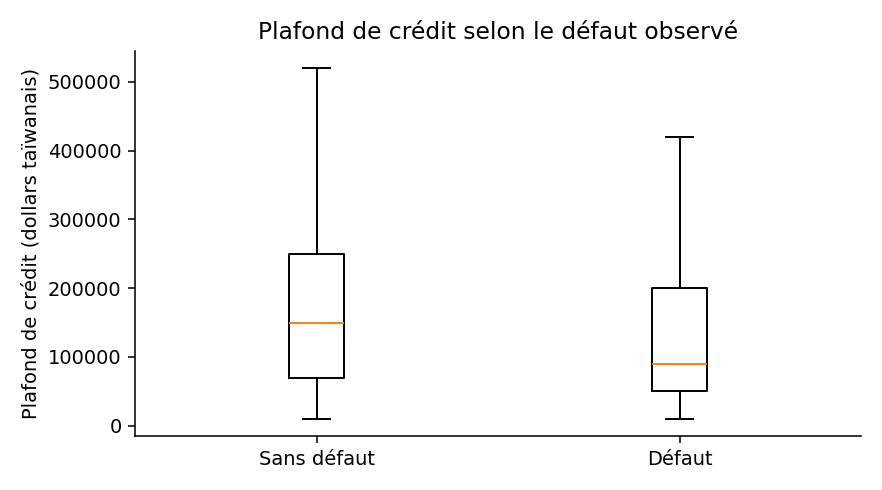

In [4]:
fig,ax=plt.subplots(figsize=(6.3,3.5))
ax.boxplot([df.loc[df.DEFAULT==k,'LIMIT_BAL'] for k in [0,1]],tick_labels=['Sans défaut','Défaut'],showfliers=False)
ax.set(ylabel='Plafond de crédit (dollars taïwanais)',title='Plafond de crédit selon le défaut observé')
fig.tight_layout();fig.savefig(ROOT/'figures'/'03_plafond.png');plt.close(fig)
print(df.groupby('DEFAULT').LIMIT_BAL.agg(['mean','median']).round(2).to_string())

## Protocole d'évaluation
La cible vaut 1 en cas de défaut le mois suivant. Il ne s'agit ni de fraude ni d'une mesure complète de surendettement.

Séparation approximative 60 % apprentissage, 20 % validation, 20 % test, stratifiée et groupée par profil explicatif identique. Les six mois de chaque client restent dans une seule ligne ; aucune séparation par mois n'est simulée. Faute de plusieurs cohortes de prédiction, cette partition ne mesure pas une généralisation à de nouvelles périodes.

Les transformations sont apprises uniquement dans le pipeline d'entraînement, y compris à chaque pli de validation croisée. L'average precision (AP, résumé de la courbe précision-rappel) est la métrique principale ; AUC-ROC, précision, rappel, F1 et exactitude complètent la lecture. Le seuil initial de 0,5 est fixé à l'avance. Les coûts économiques des erreurs ne sont pas connus : aucun seuil « optimal pour la banque » n'est annoncé.

In [5]:
X=df.drop(columns=['ID','DEFAULT']).copy();y=df.DEFAULT.copy()
X['EDUCATION']=X.EDUCATION.where(X.EDUCATION.isin([1,2,3,4]),0)
groups=pd.util.hash_pandas_object(X,index=False).astype(str)
fold=np.full(len(df),-1)
for k,(_,idx) in enumerate(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42).split(X,y,groups)):
 fold[idx]=k
train_idx=np.flatnonzero(fold>=2);val_idx=np.flatnonzero(fold==1);test_idx=np.flatnonzero(fold==0)
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[val_idx]))
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
assert not (set(groups.iloc[val_idx]) & set(groups.iloc[test_idx]))
partition=np.where(fold==0,'test',np.where(fold==1,'validation','apprentissage'))
pd.DataFrame({'ID':df.ID,'partition':partition}).to_csv(ROOT/'partitions.csv',index=False)
print(pd.DataFrame({'partition':partition,'defaut':y}).groupby('partition').agg(n=('defaut','size'),taux_defaut=('defaut','mean')).round(4).to_string())
cat=['SEX','EDUCATION','MARRIAGE','PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
num=[c for c in X if c not in cat]
def preprocessing():
 return ColumnTransformer([
  ('numeriques',Pipeline([('imputation',SimpleImputer(strategy='median')),('echelle',StandardScaler())]),num),
  ('categories',Pipeline([('imputation',SimpleImputer(strategy='most_frequent')),('encodage',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
models={
 'Référence majoritaire':DummyClassifier(strategy='most_frequent'),
 'Logit pondéré':LogisticRegression(max_iter=1500,class_weight='balanced',random_state=42),
 'Forêt aléatoire':RandomForestClassifier(n_estimators=100,min_samples_leaf=5,class_weight='balanced_subsample',random_state=42,n_jobs=2)}
Xtr=X.iloc[train_idx];ytr=y.iloc[train_idx];Xval=X.iloc[val_idx];yval=y.iloc[val_idx]
cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=123)
rows=[]; fitted={}
for name,model in models.items():
 pipe=Pipeline([('pretraitement',preprocessing()),('modele',model)])
 ap=cross_val_score(pipe,Xtr,ytr,groups=groups.iloc[train_idx],cv=cv,scoring='average_precision',n_jobs=1)
 pipe.fit(Xtr,ytr); proba=pipe.predict_proba(Xval)[:,1];pred=(proba>=.5).astype(int)
 row={'modele':name,'AP_CV_moyenne':ap.mean(),'AP_CV_ecart_type':ap.std(),
 'AP_validation':average_precision_score(yval,proba),'AUC_ROC':roc_auc_score(yval,proba),
 'accuracy':accuracy_score(yval,pred),'precision':precision_score(yval,pred,zero_division=0),
 'rappel':recall_score(yval,pred),'F1':f1_score(yval,pred),'matrice':confusion_matrix(yval,pred).tolist()}
 rows.append(row);fitted[name]=(pipe,proba,pred)
results=pd.DataFrame(rows)
results.drop(columns='matrice').to_csv(ROOT/'resultats_validation.csv',index=False)
print(results.drop(columns='matrice').round(4).to_string(index=False))
for r in rows: print(r['modele'],'matrice [[VN,FP],[FN,VP]] :',r['matrice'])
(ROOT/'resultats.json').write_text(json.dumps(rows,indent=2,ensure_ascii=False))

                   n  taux_defaut
partition                        
apprentissage  17999       0.2212
test            6000       0.2212
validation      6001       0.2213
               modele  AP_CV_moyenne  AP_CV_ecart_type  AP_validation  AUC_ROC  accuracy  precision  rappel     F1
Référence majoritaire         0.2212            0.0000         0.2213   0.5000    0.7787     0.0000  0.0000 0.0000
        Logit pondéré         0.5447            0.0106         0.5356   0.7570    0.7720     0.4873  0.5768 0.5283
      Forêt aléatoire         0.5543            0.0125         0.5434   0.7701    0.7945     0.5354  0.5414 0.5384
Référence majoritaire matrice [[VN,FP],[FN,VP]] : [[4673, 0], [1328, 0]]
Logit pondéré matrice [[VN,FP],[FN,VP]] : [[3867, 806], [562, 766]]
Forêt aléatoire matrice [[VN,FP],[FN,VP]] : [[4049, 624], [609, 719]]


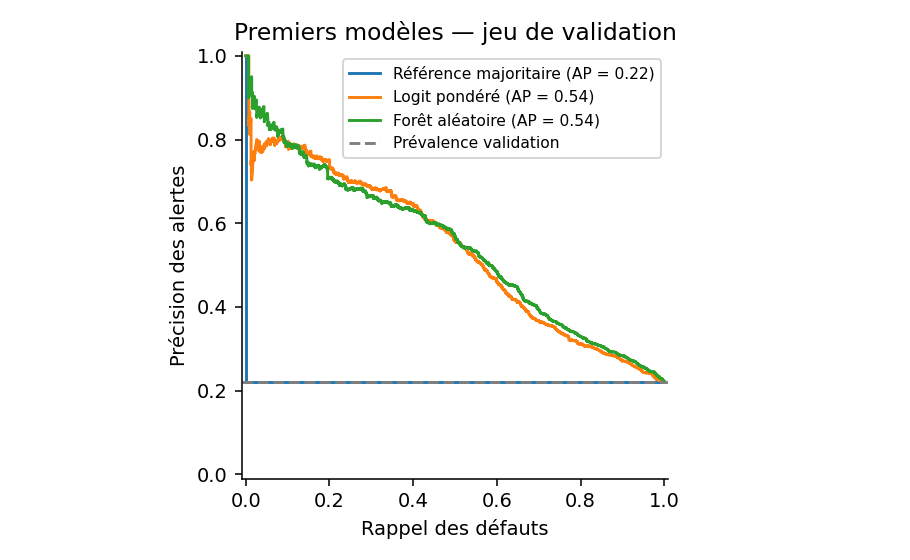

In [6]:
fig,ax=plt.subplots(figsize=(6.5,4))
for name,(_,proba,_) in fitted.items():
 PrecisionRecallDisplay.from_predictions(yval,proba,name=name,ax=ax)
ax.axhline(yval.mean(),color='gray',linestyle='--',label='Prévalence validation')
ax.set(xlabel='Rappel des défauts',ylabel='Précision des alertes',title='Premiers modèles — jeu de validation')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(ROOT/'figures'/'04_precision_rappel.png');plt.close(fig)

## Ce qui reste à faire
1. Compléter l'état de l'art : l'article associé à la base (Yeh et Lien, 2009) est un point de départ historique, à compléter par des travaux récents sur le scoring de crédit et la calibration.
2. Optimiser les hyperparamètres par RandomizedSearchCV uniquement sur l'apprentissage avec validation croisée groupée ; ajouter un gradient boosting.
3. Comparer pondération des classes et modèles non pondérés. La pondération peut dégrader la calibration : vérifier courbes de calibration et Brier score.
4. Tester des variables construites (ratio encours/plafond, moyenne des paiements, indicateurs de retard), en documentant leur date de disponibilité et les dénominateurs nuls.
5. Étudier les faux négatifs/faux positifs, l'importance par permutation et la sensibilité au retrait des variables démographiques.
6. Choisir un seuil sur la validation pour un compromis explicite, puis une seule évaluation finale sur le test. Un coût simulé devra être présenté comme une hypothèse, pas une économie observée.
7. Finaliser le rapport pour le 10 décembre et la soutenance pour le 14 décembre 2026.

**Limites :** données anciennes et localisées ; absence de revenu et de pertes réalisées ; absence d'observations sur les demandes refusées ; biais de sélection des détenteurs de carte ; associations non causales ; effectifs et incertitude à rappeler.

**Références :** Yeh, I. (2009), Default of Credit Card Clients, UCI, DOI 10.24432/C55S3H. Yeh, I.-C. et Lien, C.-H. (2009), The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients, Expert Systems with Applications, 36(2), 2473–2480.

**Traçabilité IA :** première version du code, du cadrage et du texte produite avec ChatGPT à la demande de l'étudiant ; calculs exécutés sur la base UCI. Relire, comprendre et adapter l'ensemble avant remise, selon les consignes de l'enseignante. Aucune lecture exhaustive de la littérature ni recherche d'hyperparamètres n'est revendiquée.